In [1]:
import pathlib

import navis.interfaces.neuprint as neu
import numpy as np
from matplotlib import pyplot as plt

import el_hd_plasticity.connectomics as cn
from el_hd_plasticity.connectomics import connectivity, plotting
from el_hd_plasticity.connectomics import synapse_distance as sd

plt.rcParams['pdf.fonttype'] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

figfolder = pathlib.Path('/media/mplitt/SSD_storage/fig_scratch/EL_connectomics')
figfolder.mkdir(parents=True, exist_ok=True)
syndist_folder = figfolder / 'syn_distances'      # written by el_hd_plasticity.connectomics.run_*synapse_distance
client = cn.npt_client()

In [2]:
c = nmp.connectomics.npt_client()

In [3]:
ebcoords = nmp.connectomics.EBCoordinateSystem()

/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/src/el_hd_plasticity/connectomics/connectomics.py:222: UserWarning: 
The coefficients of the spline returned have been computed as the
minimal norm least-squares solution of a (numerically) rank deficient
system (deficiency=92). If deficiency is large, the results may be
inaccurate. Deficiency may strongly depend on the value of eps.
  self._xsec_rad_spline = sp.interpolate.LSQBivariateSpline(eb_phase, xsec_phase, xsec_rad, knots, knots)


In [4]:
epgs, _ = neu.queries.fetch_neurons(neu.NeuronCriteria(type = 'EPG'))
example_epg = neu.fetch_skeletons(epgs.iloc[0]['bodyId'])

In [5]:
# 
els, _ = neu.queries.fetch_neurons(neu.NeuronCriteria(type = 'EL'))
example_el = neu.fetch_skeletons(els.iloc[0]['bodyId'])

In [6]:
eb = neu.fetch_roi("EB")
eb.vertices = ebcoords.eb_vertices
eb.vertices[:,1] = -eb.vertices[:,1]  # flip y axis to match EB coordinates
eb.vertices[:,2] = -eb.vertices[:,2]


In [7]:
# find epg - el synapses
el_syn = neu.fetch_synapse_connections(neu.NeuronCriteria(type = 'EL'), neu.NeuronCriteria(type = 'EPG'), synapse_criteria=neu.SynapseCriteria(rois=('EB')))
# er_syn = neu.fetch_synapse_connections(neu.NeuronCriteria(type = 'ER4d'), neu.NeuronCriteria(type = 'EL'), synapse_criteria=neu.SynapseCriteria(rois=('EB')))
# er2_syn = neu.fetch_synapse_connections(neu.NeuronCriteria(type = ['ER2_c','ER2_a', 'ER2_b', 'ER2_d']), neu.NeuronCriteria(type = 'EL'), synapse_criteria=neu.SynapseCriteria(rois=('EB')))
er_syn = neu.fetch_synapse_connections(neu.NeuronCriteria(type = ['ER4d', 'ER2.*']), neu.NeuronCriteria(type = 'EPG'), synapse_criteria=neu.SynapseCriteria(rois=('EB')))

nmp.add_eb_coords(el_syn, ebcoords)
nmp.add_eb_coords(er_syn, ebcoords)
# nmp.add_eb_coords(er2_syn, ebcoords)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/5773 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

... (61 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

,bodyId_pre,bodyId_post,roi_pre,roi_post,x_pre,y_pre,z_pre,x_post,y_post,z_post,...,phase,radius,radius_scaled,xsec_phase,xsec_radius,xsec_radius_scaled,xsec_x,xsec_y,xsec_x_scaled,xsec_y_scaled
0,5813077556,387364605,EB,EB,23556,25583,20951,23533,25589,20939,...,-2.759945,2463.661963,0.587771,-2.740129,103.975118,0.047725,-95.708060,-40.629943,-0.043931,-0.018649
1,5813077556,387364605,EB,EB,22870,25393,20031,22872,25399,20018,...,-3.108239,3088.518298,0.663682,2.761926,535.143897,0.217944,-497.035335,198.330196,-0.202424,0.080772
2,5813077556,387364605,EB,EB,22913,25324,20140,22901,25304,20157,...,-3.078982,3042.905395,0.663052,2.143922,339.980646,0.173654,-184.358248,285.655170,-0.094166,0.145906
3,5813077556,387364605,EB,EB,22371,25633,21077,22383,25621,21050,...,-2.801583,3610.604619,0.825037,0.356668,952.224472,0.512486,892.296707,332.472602,0.480233,0.178936
4,5813077556,387364605,EB,EB,22278,25926,21162,22278,25965,21161,...,-2.747513,3776.414741,0.873094,-0.203892,1348.697279,0.797796,1320.760226,-273.087486,0.781270,-0.161540
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34079,1105834722,5813080838,EB,EB,30226,26201,20534,30212,26174,20536,...,0.055828,4255.516109,0.889753,-0.713407,1194.705741,0.916062,903.360490,-781.832228,0.692668,-0.599484
34080,1105834722,5813080838,EB,EB,29561,26125,20826,29579,26105,20815,...,-0.023821,3668.636802,0.760892,-1.220677,634.066618,0.505879,217.491409,-595.598827,0.173522,-0.475188
34081,1105834722,5813080838,EB,EB,29328,25744,20064,29326,25750,20051,...,0.211307,3368.411065,0.724793,-0.845820,555.657772,0.377963,368.466549,-415.918215,0.250634,-0.282911
34082,1105834722,5813080838,EB,EB,30196,25439,20263,30210,25444,20278,...,0.175786,4265.335405,0.903138,-0.120679,1102.135156,0.732011,1094.119482,-132.681805,0.726688,-0.088124


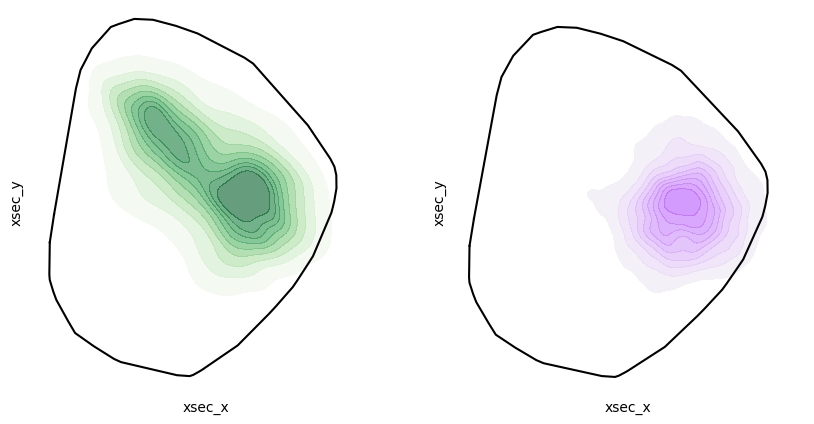

In [8]:
fig, ax= plt.subplots(1,2, figsize=(10, 5))
magentas = sns.light_palette(plt.cm.cool(.7), as_cmap=True)

sns.kdeplot(
    data=el_syn, x="xsec_x", y="xsec_y", fill=True, ax=ax[0], cmap='Greens', alpha=.6
)
sns.kdeplot(
    data=er_syn, x="xsec_x", y="xsec_y", fill=True, ax=ax[1], cmap=magentas, alpha=.6
)

r,p = ebcoords.eb_vertices_xsec['radius'], ebcoords.eb_vertices_xsec['phase']
c = np.column_stack((r*np.cos(p), r*np.sin(p)))
# c = np.column_stack((ebcoords.eb_vertices_circ['radius'], ebcoords.eb_vertices[:,2]))

hull = sp.spatial.ConvexHull(c)
hull_points = c[hull.vertices,:]
for a in ax.flatten():
    a.plot(hull_points[:,0], hull_points[:,1], color='black')
    a.plot([hull_points[-1,0], hull_points[0,0]], [hull_points[-1,1], hull_points[0,1]], color='black')

    a.set_xticks([])
    a.set_yticks([])
    for b in ['top', 'right', 'left', 'bottom']:
            a.spines[b].set_visible(False)

# fig.savefig(figfolder / 'epg_er_synapse_density_xsec.pdf')


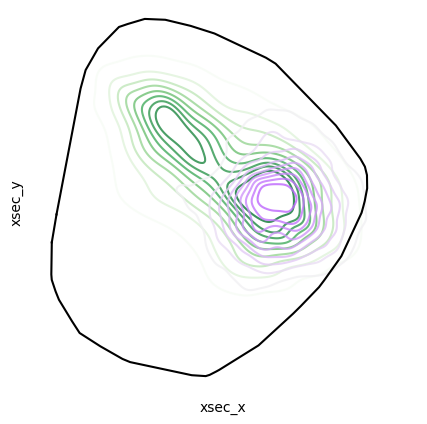

In [9]:
fig, ax= plt.subplots(figsize=(5, 5))


sns.kdeplot(
    data=el_syn, x="xsec_x", y="xsec_y", fill=False, ax=ax, cmap='Greens', alpha=.8
)
sns.kdeplot(
    data=er_syn, x="xsec_x", y="xsec_y", fill=False, ax=ax, cmap=magentas, alpha=.8
)



r,p = ebcoords.eb_vertices_xsec['radius'], ebcoords.eb_vertices_xsec['phase']
c = np.column_stack((r*np.cos(p), r*np.sin(p)))
# c = np.column_stack((ebcoords.eb_vertices_circ['radius'], ebcoords.eb_vertices[:,2]))

hull = sp.spatial.ConvexHull(c)
hull_points = c[hull.vertices,:]

ax.plot(hull_points[:,0], hull_points[:,1], color='black')
ax.plot([hull_points[-1,0], hull_points[0,0]], [hull_points[-1,1], hull_points[0,1]], color='black')

ax.set_xticks([])
ax.set_yticks([])
for b in ['top', 'right', 'left', 'bottom']:
    ax.spines[b].set_visible(False)

In [10]:
# load 2 ER4ds

# load EPG that gets the most combined inputs from these 2

# load 1 EL



In [12]:
example_er4d_bodyId = er4ds['bodyId'].iloc[3]
neuron_df, conn_df = neu.queries.fetch_adjacencies(els['bodyId'], example_er4d_bodyId, rois='EB')
conn_df.sort_values('weight', ascending=False, inplace=True)
example_el_bodyId = conn_df['bodyId_pre'].iloc[0].copy()

NameError: name 'er4ds' is not defined

NameError: name 'er4d_skel' is not defined

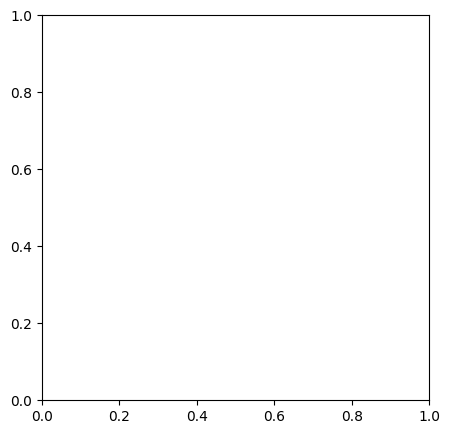

In [11]:
fig, ax = plt.subplots(figsize=(5, 5))
_ = navis.plot2d(
                [er4d_skel], #[eb, er4d_skel],
                method="2d",
                connectors=False,
                linewidth=1.,  # Make neuron a bit thinner to emphasize the synapses
                view=("x", "y"),
                # depth_coloring=True,
                # palette='cool',
                shade_by='z',
                smin=-2000, smax=700,
                color=(plt.cm.cool(.7)), 
                     #   plt.cm.Greys(.3)),
                alpha=1,
                radius=True,
                ax=ax,
            )
ax.grid(False)

ax.scatter(er4d_epg_synapses.loc[:,'x_eb'], 
           er4d_epg_synapses.loc[:,'y_eb'],
           s=80, color='black',zorder=101) #plt.cm.Greys(.8))

ax.scatter(el_er4d_synapses.loc[:,'x_eb'],
           el_er4d_synapses.loc[:,'y_eb'],
           s=80, color='green',zorder=100) #color=plt.cm.Greens(.8))

ax.set_xlim([-5100, -2000])
ax.set_ylim([-300,2400])
ax.plot([-3200,-3200+1000/8*5],[0, 0], linewidth=5, color='black') # 5 micron line

ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('')
ax.set_ylabel('')
for s in ['top', 'left', 'bottom', 'right']:
       ax.spines[s].set_visible(False)

fig.savefig(figfolder / "er4d_epg_el_examples_synapses_xy.png", dpi=500, transparent=True)


fig, ax = plt.subplots(figsize=(5, 5))
_ = navis.plot2d(
                [er4d_skel], #[eb, er4d_skel],
                method="2d",
                connectors=False,
                linewidth=1.,  # Make neuron a bit thinner to emphasize the synapses
                view=("x", "z"),
                color=(plt.cm.cool(.7)), 
                    #    plt.cm.Greys(.3)),
                shade_by='y',
                smin=5, smax= 1800,
                alpha=1,
                radius=True,
                ax=ax,
            )
ax.grid(False)

ax.scatter(er4d_epg_synapses.loc[:,'x_eb'], 
           er4d_epg_synapses.loc[:,'z_eb'],
           s=80, color=plt.cm.Greys(.8),zorder=101) #plt.cm.Greys(.8))

ax.scatter(el_er4d_synapses.loc[:,'x_eb'],
           el_er4d_synapses.loc[:,'z_eb'],
           s=80, color=plt.cm.brg(.99),zorder=100) #color=plt.cm.Greens(.8))

ax.set_xlim([-5100, -2000])
ax.set_ylim([-2000,1500])
ax.plot([-3200,-3200+1000/8*5],[1200, 1200], linewidth=5, color='black') # 5 micron line

ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('')
ax.set_ylabel('')
for s in ['top', 'left', 'bottom', 'right']:
       ax.spines[s].set_visible(False)

# fig.savefig(figfolder / "er4d_epg_el_examples_synapses_xz.png", dpi=500, transparent=True)